# 2. How the detector works

The pipeline answers two questions for every area:

* **Level:** is the share of recent infections here higher (or lower) than in the
  rest of the country now?
* **Trend:** has it risen (or fallen) compared with this area's own past?

The answers are combined into one label, and every label carries a **reliability**
rating that says how much data stands behind it. This notebook walks through the
steps on the synthetic data.

In [1]:
# In the browser (JupyterLite) install the packages this notebook needs.
# On a normal Python kernel this cell does nothing.
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["pandas", "geopandas", "shapely", "pyproj", "matplotlib", "scipy"])

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta
from hotspots_lite import build_info, load_results, load_oblasts, plot_labels, LABEL_COLORS

info = build_info()
cells = load_results()
active = cells[cells["tests_curr"].fillna(0) > 0].copy()
print(f"Analysis window {info['window_start']} to {info['window_end']}")
print(f"{len(cells)} H3 cells cover Ukraine; {len(active)} have testing in the window")
active[["name", "oblast", "tests_curr", "recent_curr", "tests_hist", "recent_hist"]].sort_values(
    "recent_curr", ascending=False).head(10)

Analysis window 2025-12-01 to 2026-05-31
82 H3 cells cover Ukraine; 26 have testing in the window


,name,oblast,tests_curr,recent_curr,tests_hist,recent_hist
73,Hex in Verbkivska,Dnipropetrovska,138.0,7.0,241.0,4.0
22,Hex in Kostiantynivska,Zaporizka,93.0,4.0,140.0,6.0
37,Hex in Kozeletska,Chernihivska,41.0,4.0,94.0,1.0
39,Hex in Vasylkivska,Kyivska,264.0,3.0,584.0,8.0
25,Hex in Lozuvatska,Dnipropetrovska,105.0,3.0,261.0,2.0
49,Hex in Drabivska,Cherkaska,7.0,2.0,4.0,1.0
71,Hex in Boikivska,Donetska,11.0,1.0,54.0,0.0
35,Hex in Vasylivska,Odeska,76.0,1.0,150.0,0.0
69,Hex in Shakhivska,Donetska,10.0,1.0,45.0,0.0
14,Hex in Haivoronska,Kirovohradska,10.0,0.0,25.0,0.0


## Step 1. From sites to areas

Every test belongs to a testing site, and every site falls in one area. Here the
areas are **H3 hexagons at resolution 3** (about 12,000 km² each); the pipeline also
works on oblasts. An area's data are simply the sums over its sites: tests and recent
results in the analysis window and in the baseline window. The denominator is the
number of **tests**, not the population, because nobody knows exactly whom a site
serves.

## Step 2. Level: compared with the rest of the country

For each area the model estimates its recent share *p* and asks how likely it is that
*p* is above the national share **computed without that area** (leave-one-out, so a
large area does not pull the reference towards itself). An area is called *above* (or
*below*) when that posterior probability is at least **0.80**. This is the decision
rule of Richardson et al. (2004) for disease maps; a simulation on sparse data like
ours picked 0.80 as the best balance between missed signals and false alarms. Where
the data allow it, the cutoff is raised further so that the expected share of false
calls among flagged areas stays within 5 %.

The production model is a hierarchical Bayesian model (notebook 5 runs it). The cell
below shows the same rule on a much simpler posterior, a Beta distribution per area,
so you can see the mechanics in a second.

In [3]:
recent_total, tests_total = active["recent_curr"].sum(), active["tests_curr"].sum()
national = recent_total / tests_total
loo = (recent_total - active["recent_curr"]) / (tests_total - active["tests_curr"])

prior_strength = 20                      # pseudo-tests pulling small areas towards the national share
a0, b0 = national * prior_strength, (1 - national) * prior_strength
post_a = a0 + active["recent_curr"]
post_b = b0 + active["tests_curr"] - active["recent_curr"]
active["P(above rest of country)"] = 1 - beta.cdf(loo, post_a, post_b)

print(f"National recent share in the window: {national:.3%} ({int(recent_total)} of {int(tests_total)} tests)")
cols = ["name", "tests_curr", "recent_curr", "P(above rest of country)", "label"]
active.sort_values("P(above rest of country)", ascending=False)[cols].head(8).round(3)

National recent share in the window: 1.481% (26 of 1755 tests)


,name,tests_curr,recent_curr,P(above rest of country),label
73,Hex in Verbkivska,138.0,7.0,0.998,Stable high-burden
37,Hex in Kozeletska,41.0,4.0,0.996,Stable high-burden
49,Hex in Drabivska,7.0,2.0,0.974,Elevated vs national (trend uncertain)
22,Hex in Kostiantynivska,93.0,4.0,0.957,Stable high-burden
25,Hex in Lozuvatska,105.0,3.0,0.808,Normal
69,Hex in Shakhivska,10.0,1.0,0.781,Normal
71,Hex in Boikivska,11.0,1.0,0.772,Normal
35,Hex in Vasylivska,76.0,1.0,0.344,Normal


Two things stand out. First, with one or two per cent of tests recent, an area needs
both a fair number of tests and several recent results before the probability passes
0.80. Second, the simple posterior and the pipeline's label (last column) mostly agree
but not always: the hierarchical model learns how much areas really differ and shrinks
noisy areas more firmly towards the national level.

## Step 3. Trend: compared with the area's own past

The production model fits both windows **jointly**: each area has its own level and
its own change between the baseline and the analysis window, and the change is
partially pooled towards the national change. An area is *rising* when the posterior
probability of a positive change is at least 0.80. Pooling matters here, because many
areas have no recent results at all in one of the windows.

## Step 4. Labels

| Trend \ Level | above the country | similar | below the country |
|---|---|---|---|
| **rising** | Established hotspot | Emerging hotspot | Normal |
| **stable** | Stable high-burden | Normal | Below national |
| **falling** | Declining from high-burden | Emerging decrease | Below national |

Two gates protect against false alarms caused by zeros:

* **presence gate:** a hotspot label needs at least **two recent results** in the
  analysis window; an area cannot be a hotspot of recent infection without them;
* **cold-cell gate:** an area with no recent results in either window has no trend to
  speak of and is *Normal*.

When an area's own history is too thin to judge a trend, an elevated area is labelled
*Elevated vs national (trend uncertain)* rather than being given a direction.

In [4]:
cells["label"].value_counts(dropna=True).rename("areas").to_frame()

,areas
label,
Normal,22
Stable high-burden,3
Elevated vs national (trend uncertain),1


## Step 5. Reliability

Every estimate comes with a rating that depends on how wide its 95 % credible interval
is relative to the estimate itself (its coefficient of variation, CV):

score = 100 × exp(−CV); **HIGH** ≥ 80, **MODERATE** ≥ 60, otherwise **LOW**.

A calibration study showed that HIGH estimates are almost always decisive about the
national reference and LOW ones almost never. Maps **hatch** LOW areas so that a reader
sees at once which colours rest on too little data. Separately, if the sampler does not
converge (R-hat ≥ 1.01 or effective sample size ≤ 400), the run is marked unreliable as
a whole.

reliability
LOW    26


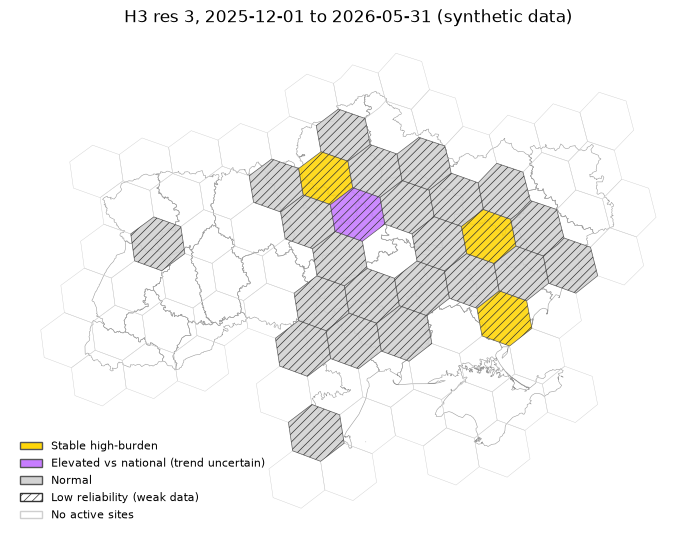

In [5]:
print(cells["reliability"].value_counts().to_string())
plot_labels(cells, oblasts=load_oblasts(),
            title=f"H3 res 3, {info['window_start']} to {info['window_end']} (synthetic data)")
plt.show()

## What the method cannot do

With a few dozen recent results per window across the country, most areas are LOW
reliability **by nature of the data**, not because of the thresholds. The method is
built to say so openly: it labels only what the data can support, hatches what they
cannot, and never invents a trend from a single count. Locations are those of testing
sites, not of where people live.